In [33]:
import sys
import os
base_dir = r"C:\Users\acostamendoza\projects\distance-project"
data_dir = r"D:\data-distance-coding-project\processed-data"
sys.path.append(base_dir)
from src.data.RadialDevice import RadialDevice
from src.viz.SessionVisualizer import SessionVisualizer
from src.viz.CellVisualizer import CellVisualizer
from src.analysis.CellAnalysis import CellAnalyzer, SessionAnalyzer

import numpy as np
import matplotlib.pyplot as plt
import pickle
from scipy.optimize import curve_fit
from src.workflows import load_dataframe

%load_ext autoreload
%autoreload 2

mouse_name = 'SAM043'
record_date = '251213'
experiment_name = 'tiling_5_120um'

device = RadialDevice(mouse_name = mouse_name, record_date = record_date, experiment_name = experiment_name)
session_df = load_dataframe(mouse_name = mouse_name, record_date = record_date, experiment_name = experiment_name)
viz = SessionVisualizer(session_df, animal_id = mouse_name, experiment_name = experiment_name)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
[ok] Loading session: 251213_SAM043_tiling_5_120um
Directory results already exists
Successfully loaded activity data
Stimulus file found
Repeat stimulus on length distribution:
    98 repeats have length 61
    22 repeats have length 62
Set stimulus on length: 61
[ok] Loaded DataFrame from D:/data-distance-coding-project/processed-data\251213_SAM043_tiling_5_120um\251213_SAM043_tiling_5_120um_dataframe.pkl (1161 cells)


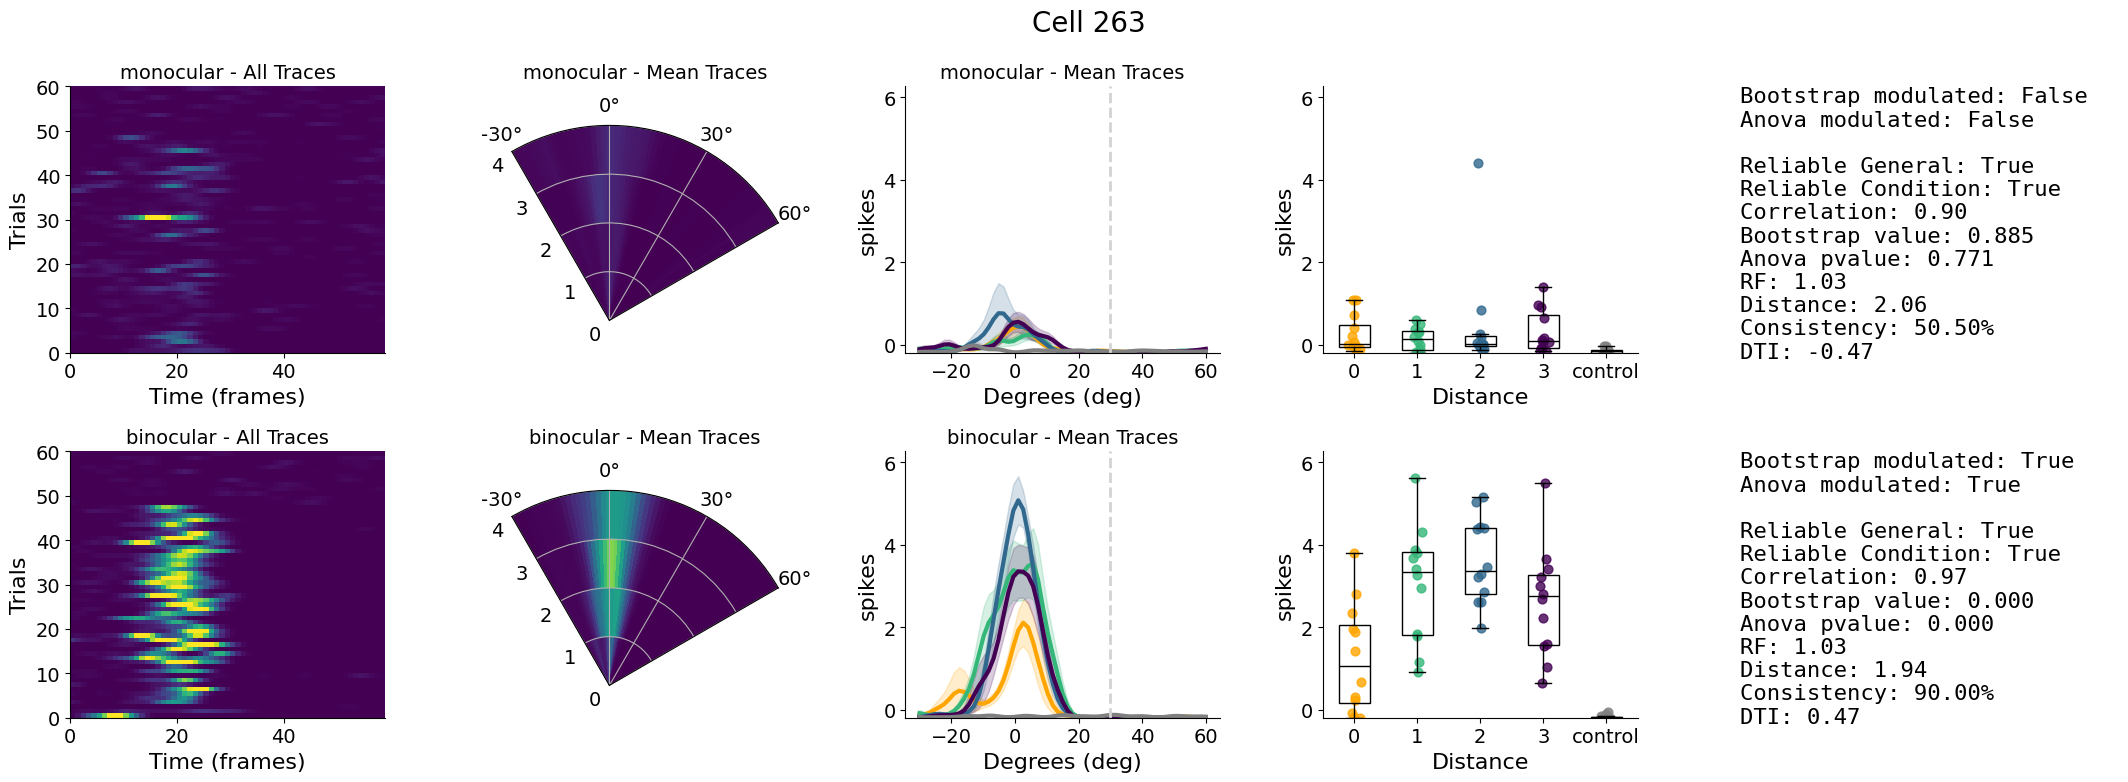

In [ ]:
analyzer = CellAnalyzer(device)
cell_viz = CellVisualizer(device, analyzer)
fig = cell_viz.plot_all_traces_colormap_distances(263)

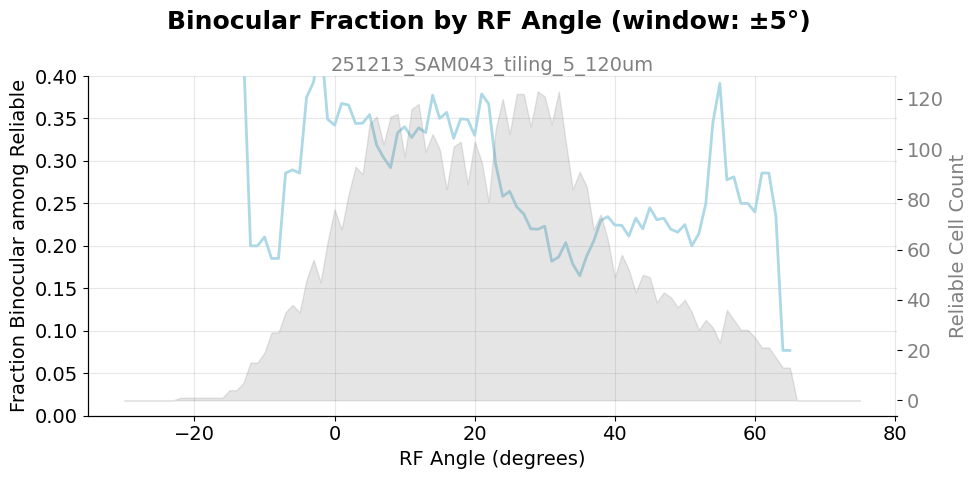

In [34]:
fig =viz.plot_modulation_fraction_by_angle()

In [10]:
# =============================================================================
# NON-PARAMETRIC MLE DECODER FOR DISTANCE (CONTINUOUS OUTPUT)
# =============================================================================

def compute_empirical_tuning_by_distance(cell, train_trials_by_distance):
    """
    Compute empirical mean and variance of response at each angle FOR EACH DISTANCE.

    Parameters
    ----------
    cell : cell ID
    train_trials_by_distance : dict mapping distance (0-3) to trial indices

    Returns
    -------
    means : array (n_distances, n_angles) - mean response at each angle for each distance
    variances : array (n_distances, n_angles) - variance at each angle for each distance
    """
    n_distances = 4
    n_angles = len(device.angle_range)

    means = np.zeros((n_distances, n_angles))
    variances = np.zeros((n_distances, n_angles))

    for dist in range(n_distances):
        trial_responses = np.array([
            device.get_repeat_trace(cell, trial_idx)
            for trial_idx in train_trials_by_distance[dist]
        ])  # Shape: (n_trials_for_dist, n_angles)

        means[dist] = np.mean(trial_responses, axis=0)
        variances[dist] = np.var(trial_responses, axis=0)

    return means, variances


def compute_all_neuron_stats_by_distance(cells_to_include, train_trials_by_distance):
    """
    Compute empirical tuning statistics for all neurons, organized by distance.

    Returns
    -------
    neuron_means : array (n_neurons, n_distances, n_angles)
    neuron_variances : array (n_neurons, n_distances, n_angles)
    """
    n_neurons = len(cells_to_include)
    n_distances = 4
    n_angles = len(device.angle_range)

    neuron_means = np.zeros((n_neurons, n_distances, n_angles))
    neuron_variances = np.zeros((n_neurons, n_distances, n_angles))

    for i, cell in enumerate(cells_to_include):
        means, variances = compute_empirical_tuning_by_distance(cell, train_trials_by_distance)
        neuron_means[i] = means
        neuron_variances[i] = variances

    return neuron_means, neuron_variances


def log_likelihood_distance(response_vector, angle_idx, distance_idx, neuron_means, neuron_variances):
    """
    Compute Gaussian log-likelihood of observing response at given angle under a specific distance class.

    Parameters
    ----------
    response_vector : array (n_neurons,) - observed response at one angle
    angle_idx : int - index into angle_range
    distance_idx : int - distance class (0, 1, 2, or 3)
    neuron_means : array (n_neurons, n_distances, n_angles)
    neuron_variances : array (n_neurons, n_distances, n_angles)

    Returns
    -------
    ll : float - log-likelihood value
    """
    expected = neuron_means[:, distance_idx, angle_idx]
    variances = neuron_variances[:, distance_idx, angle_idx]

    # Add small epsilon to avoid division by zero
    variances = np.maximum(variances, 1e-6)

    # Gaussian log-likelihood (constant terms dropped since we only need argmax)
    ll = -np.sum((response_vector - expected)**2 / variances)
    return ll


def decode_distance(response_vector, angle_idx, neuron_means, neuron_variances):
    """
    Predict distance as a continuous value using posterior mean.
    
    Computes log-likelihoods for each distance class, converts to probabilities,
    and returns the expected value (weighted average of distances).
    
    Returns
    -------
    float : predicted distance as continuous value (between 0 and 3)
    """
    n_distances = 4
    distances = np.array([0, 1, 2, 3])
    
    # Compute log-likelihoods for each distance
    log_likelihoods = np.array([
        log_likelihood_distance(response_vector, angle_idx, d, neuron_means, neuron_variances)
        for d in range(n_distances)
    ])
    
    # Convert to probabilities using softmax (subtract max for numerical stability)
    log_likelihoods = log_likelihoods - np.max(log_likelihoods)
    probabilities = np.exp(log_likelihoods)
    probabilities = probabilities / np.sum(probabilities)
    
    # Return expected value (posterior mean)
    expected_distance = np.sum(distances * probabilities)
    
    return expected_distance

In [11]:
# =============================================================================
# TRAIN/TEST UTILITIES FOR DISTANCE DECODING
# =============================================================================

def get_train_test_idxs_by_distance(train_pctg, monocular=None):
    """
    Split trials into train and test sets, organized by distance.
    
    Returns
    -------
    train_trials_by_distance : dict mapping distance (0-3) to train trial indices
    all_test_trials : list of (trial_idx, actual_distance) tuples
    """
    train_trials_by_distance = {}
    all_test_trials = []

    for dist in range(4):
        trial_idxs = device.get_condition_trials(monocular=monocular, distance=dist)
        trial_idxs = np.random.permutation(trial_idxs)
        split_point = int(train_pctg * len(trial_idxs))

        train_trials_by_distance[dist] = trial_idxs[:split_point]
        test_idxs = trial_idxs[split_point:]
        all_test_trials.extend([(t, dist) for t in test_idxs])

    return train_trials_by_distance, all_test_trials


def get_test_trial_responses(cells_to_include, test_idx):
    """Get response vectors for all neurons for a single test trial."""
    test_responses = np.array([
        device.get_repeat_trace(cell, test_idx)
        for cell in cells_to_include
    ])
    return test_responses  # Shape: (n_neurons, n_angles)


def decode_distance_trajectory(cells_to_include, neuron_means, neuron_variances, test_idx):
    """
    Decode distance at each angle position for a single test trial.
    
    Returns
    -------
    decoded_distances : list of predicted distance classes (0-3) for each angle
    """
    test_responses = get_test_trial_responses(cells_to_include, test_idx)
    # test_responses shape: (n_neurons, n_angles)

    decoded_distances = []
    for angle_idx in range(test_responses.shape[1]):
        decoded_distances.append(
            decode_distance(test_responses[:, angle_idx], angle_idx, neuron_means, neuron_variances)
        )

    return decoded_distances

In [26]:
# =============================================================================
# EVALUATION FUNCTIONS FOR DISTANCE DECODING (CONTINUOUS OUTPUT)
# =============================================================================

def evaluate_distance_decoder(actual, decoded):
    """
    Compute numerical error metrics for distance decoder.
    """
    actual = np.array(actual)
    decoded = np.array(decoded)
    errors = decoded - actual
    
    metrics = {
        'mae': np.mean(np.abs(errors)),
        'rmse': np.sqrt(np.mean(errors**2)),
        'bias': np.mean(errors),
        'std': np.std(errors),
        'correlation': np.corrcoef(actual.flatten(), decoded.flatten())[0, 1],
    }
    return metrics


def plot_distance_decoder_performance(actual, decoded, angle_indices, angle_range):
    """
    Plot MAE vs angle position for distance decoder.
    """
    actual = np.array(actual)
    decoded = np.array(decoded)
    angle_indices = np.array(angle_indices)
    errors = decoded - actual
    
    metrics = evaluate_distance_decoder(actual, decoded)
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    n_angles = len(angle_range)
    mae_by_angle = np.zeros(n_angles)
    
    for ang_idx in range(n_angles):
        mask = angle_indices == ang_idx
        if mask.sum() > 0:
            mae_by_angle[ang_idx] = np.mean(np.abs(errors[mask]))
    
    ax.plot(angle_range, mae_by_angle, 'b-', linewidth=2)
    ax.axhline(metrics['mae'], color='g', linestyle='--', alpha=0.7, 
               label=f'Overall MAE = {metrics["mae"]:.2f}')
    ax.axhline(1.25, color='r', linestyle=':', alpha=0.5, label='Random guess MAE ~1.25')
    ax.set_xlabel('Angle Position (deg)')
    ax.set_ylabel('Mean Absolute Error')
    ax.set_title('Distance Decoding Error vs Angle')
    ax.set_ylim([0, 2])
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    return fig, metrics


def print_distance_metrics(metrics):
    """Pretty print the distance decoder metrics."""
    print("=" * 50)
    print("DISTANCE DECODER PERFORMANCE")
    print("=" * 50)
    print(f"  Mean Absolute Error:  {metrics['mae']:.3f}")
    print(f"  RMSE:                 {metrics['rmse']:.3f}")
    print(f"  Bias:                 {metrics['bias']:.3f}")
    print(f"  Correlation:          {metrics['correlation']:.3f}")
    print()
    print("  Reference (random guess MAE ~ 1.25)")
    print("=" * 50)

Using 531 reliable cells for distance decoding
=== Fold 20/20 ===
Total predictions: 9760
Predictions per angle: 160
DISTANCE DECODER PERFORMANCE
  Mean Absolute Error:  0.985
  RMSE:                 1.303
  Bias:                 -0.036
  Correlation:          0.202

  Reference (random guess MAE ~ 1.25)


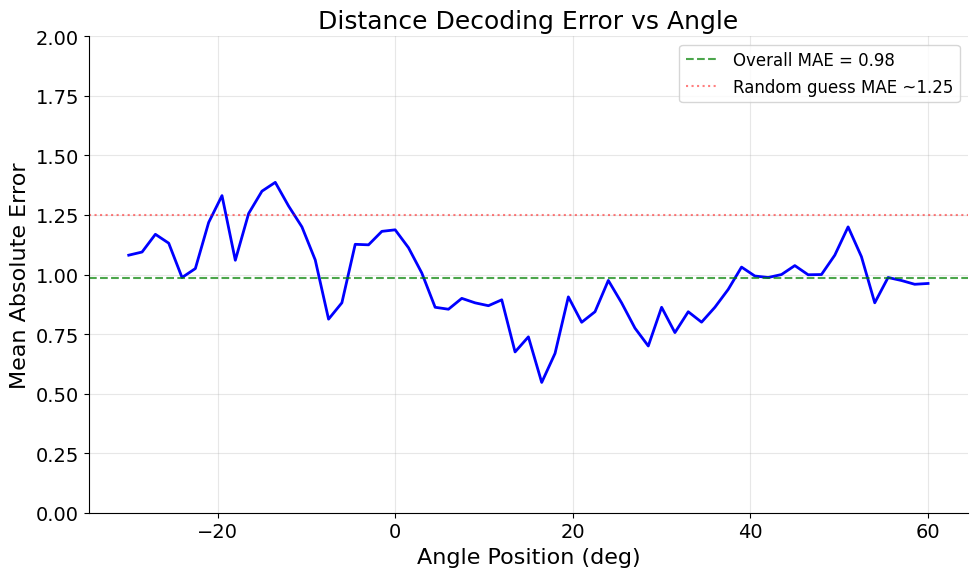

In [37]:
# =============================================================================
# RUN DISTANCE DECODER WITH K-FOLD CROSS-VALIDATION
# =============================================================================

# Identify reliable cells
monocular = False

reliable_cells_df = viz.filter_by_reliability(session_df, reliable_type='reliable', threshold=0.85)
cells_to_use = reliable_cells_df['cell_id'].values
print(f'Using {len(cells_to_use)} reliable cells for distance decoding')

# Perform k-fold cross-validation
k_folds = 20
all_decoded = []
all_actual = []
all_angle_indices = []

for fold in range(k_folds):
    print(f'=== Fold {fold + 1}/{k_folds} ===', end='\r', flush=True)

    # Get train/test split for this fold (stratified by distance)
    train_by_dist, all_test = get_train_test_idxs_by_distance(0.9, monocular=monocular)
    
    # Compute empirical tuning statistics on training data
    neuron_means, neuron_variances = compute_all_neuron_stats_by_distance(cells_to_use, train_by_dist)

    # Decode test trials
    for test_idx, actual_dist in all_test:
        decoded_trajectory = decode_distance_trajectory(cells_to_use, neuron_means, neuron_variances, test_idx)
        
        # Store results for each angle position
        all_decoded.extend(decoded_trajectory)
        all_actual.extend([actual_dist] * len(decoded_trajectory))
        all_angle_indices.extend(range(len(device.angle_range)))

print(f'\nTotal predictions: {len(all_decoded)}')
print(f'Predictions per angle: {len(all_decoded) // len(device.angle_range)}')

# Convert to arrays
all_decoded = np.array(all_decoded)
all_actual = np.array(all_actual)
all_angle_indices = np.array(all_angle_indices)

# Evaluate and plot
fig, metrics = plot_distance_decoder_performance(all_actual, all_decoded, all_angle_indices, device.angle_range)
print_distance_metrics(metrics)
plt.show()

Using 531 reliable cells for distance decoding
=== Fold 10/10 ===
Total predictions: 4880
Predictions per angle: 80
DISTANCE DECODER PERFORMANCE
  Mean Absolute Error:  1.175
  RMSE:                 1.497
  Bias:                 0.012
  Correlation:          0.040

  Reference (random guess MAE ~ 1.25)


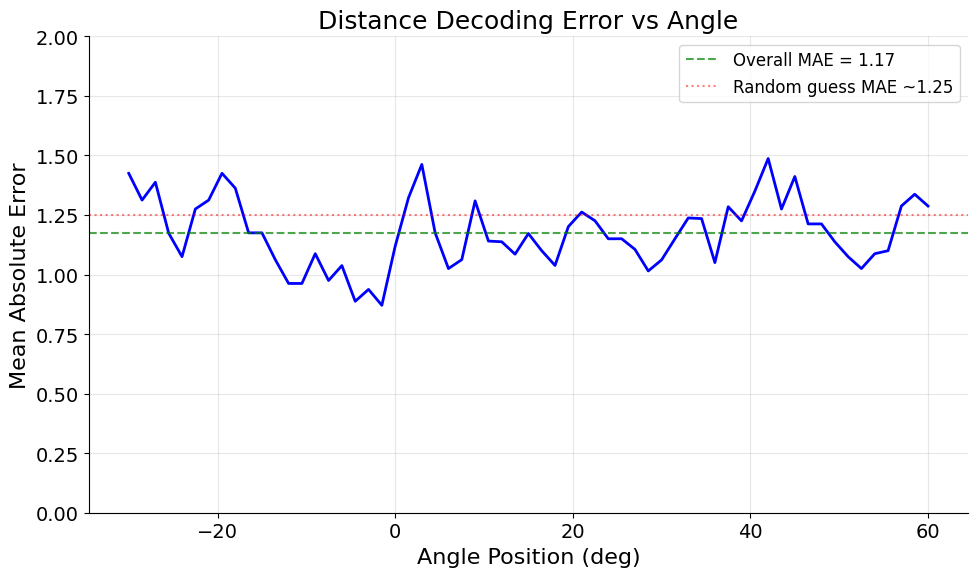

In [38]:
# =============================================================================
# RUN DISTANCE DECODER WITH K-FOLD CROSS-VALIDATION
# =============================================================================

# Identify reliable cells
monocular = True

reliable_cells_df = viz.filter_by_reliability(session_df, reliable_type='reliable', threshold=0.85)
cells_to_use = reliable_cells_df['cell_id'].values
print(f'Using {len(cells_to_use)} reliable cells for distance decoding')

# Perform k-fold cross-validation
k_folds = 10
all_decoded = []
all_actual = []
all_angle_indices = []

for fold in range(k_folds):
    print(f'=== Fold {fold + 1}/{k_folds} ===', end='\r', flush=True)

    # Get train/test split for this fold (stratified by distance)
    train_by_dist, all_test = get_train_test_idxs_by_distance(0.9, monocular=monocular)
    
    # Compute empirical tuning statistics on training data
    neuron_means, neuron_variances = compute_all_neuron_stats_by_distance(cells_to_use, train_by_dist)

    # Decode test trials
    for test_idx, actual_dist in all_test:
        decoded_trajectory = decode_distance_trajectory(cells_to_use, neuron_means, neuron_variances, test_idx)
        
        # Store results for each angle position
        all_decoded.extend(decoded_trajectory)
        all_actual.extend([actual_dist] * len(decoded_trajectory))
        all_angle_indices.extend(range(len(device.angle_range)))

print(f'\nTotal predictions: {len(all_decoded)}')
print(f'Predictions per angle: {len(all_decoded) // len(device.angle_range)}')

# Convert to arrays
all_decoded = np.array(all_decoded)
all_actual = np.array(all_actual)
all_angle_indices = np.array(all_angle_indices)

# Evaluate and plot
fig, metrics = plot_distance_decoder_performance(all_actual, all_decoded, all_angle_indices, device.angle_range)
print_distance_metrics(metrics)
plt.show()